# Read handwritten digits (OOP version)

We use the **same 2 classes** as the Maths marks problem: `Net` and `Trainer`.

| | Maths marks | Digits |
|---|---|---|
| Inputs | 2 | **64** (pixels) |
| Outputs | 1 | **10** (one score per digit) |
| Loss | `nn.MSELoss` | `nn.CrossEntropyLoss` |

We build it **step by step**. The **complete code** is at the end.

In [7]:
import numpy as np                                     # arrays of numbers
import matplotlib.pyplot as plt                        # draw pictures and charts
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # nn = "neural network": layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split data into train / validation / test
from sklearn.datasets import load_digits               # the handwritten digits pictures

## The 2 classes
Same as in `cw_OOP_Solution.ipynb`. `Net` = the map, `Trainer` = trains it and guesses.

In [8]:
def to_tensor(a, dtype=torch.float32):
    return torch.tensor(a, dtype=dtype)


class Net(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs):
        super().__init__()                          # start the nn.Module part
        self.hidden = nn.Linear(n_inputs, n_hidden) # input → hidden (weights + biases)
        self.relu = nn.ReLU()                       # activation: negative → 0
        self.output = nn.Linear(n_hidden, n_outputs)# hidden → output

    def forward(self, x):
        return self.output(self.relu(self.hidden(x)))


class Trainer:
    def __init__(self, model, loss_fn, lr):
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []

    def fit(self, X_train, y_train, X_val, y_val, epochs):
        for epoch in range(epochs):
            loss = self.loss_fn(self.model(X_train), y_train)   # 1. guess + 2. how wrong
            self.optimizer.zero_grad()                          # 3. clear old blame
            loss.backward()                                     # 4. find blame (backprop)
            self.optimizer.step()                               # 5. fix (gradient descent)
            self.train_losses.append(loss.item())
            with torch.no_grad():                               # mock exam: check only
                self.val_losses.append(self.loss_fn(self.model(X_val), y_val).item())

    def predict(self, X):
        with torch.no_grad():
            return self.model(X)

    def plot(self):
        plt.plot(self.train_losses, label="train (homework)")
        plt.plot(self.val_losses, label="validation (mock exam)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()

### Look at the data first: what do the pictures look like?

Each picture is only **8 × 8 = 64 pixels**. Every pixel is a number: **0 = white** (no ink), **16 = black** (full ink).

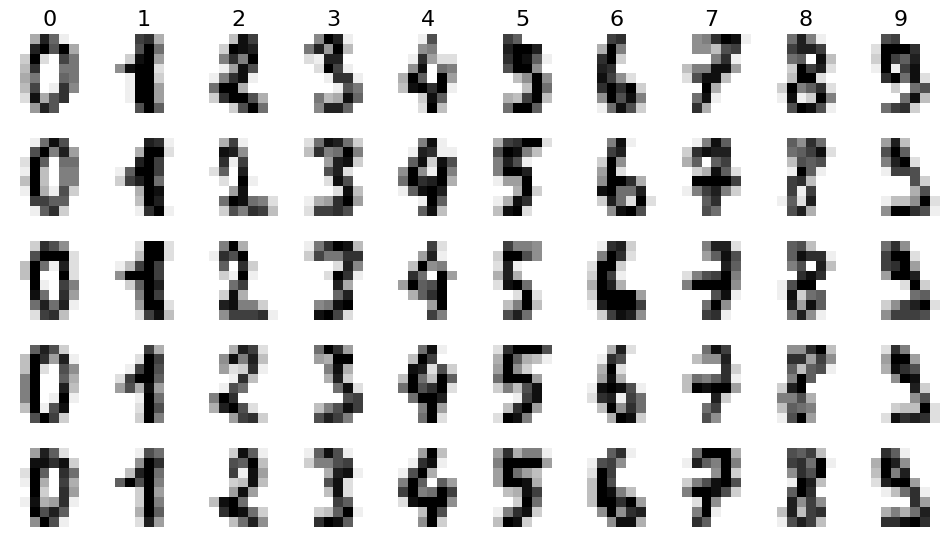

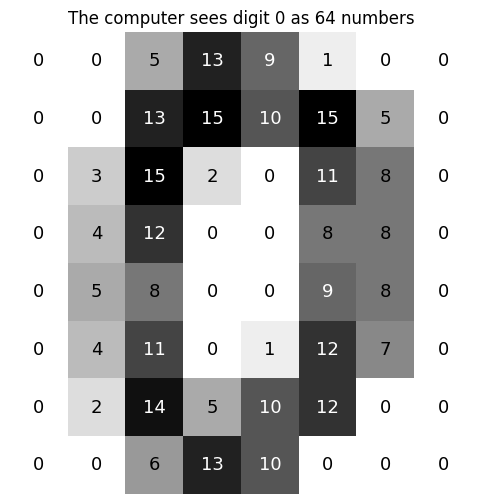

In [9]:
import numpy as np
from sklearn.datasets import load_digits

digits = load_digits()                                  # 1797 small pictures of handwritten digits

# 1. 5 examples of each digit, 0 to 9
fig, axes = plt.subplots(5, 10, figsize=(12, 6.5))      # 5 rows × 10 columns of small pictures
for digit in range(10):                                 # one column for each digit 0..9
    positions = np.where(digits.target == digit)[0][:5] # the first 5 pictures of this digit
    for row, i in enumerate(positions):
        ax = axes[row, digit]
        ax.imshow(digits.images[i], cmap="gray_r")      # draw the 8 × 8 grid (0 = white, 16 = black)
        ax.axis("off")                                  # hide the axis numbers
        if row == 0:
            ax.set_title(digit, fontsize=16)            # the digit on top of each column
plt.show()

# 2. What the computer sees: one picture with its 64 numbers
first = digits.images[0].astype(int)                    # the first picture as whole numbers
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(first, cmap="gray_r")
for r in range(8):                                      # write each pixel's number on top of it
    for c in range(8):
        color = "white" if first[r, c] > 8 else "black" # white text on dark pixels, so we can read it
        ax.text(c, r, first[r, c], ha="center", va="center", color=color, fontsize=13)
ax.set_title(f"The computer sees digit {digits.target[0]} as 64 numbers")
ax.axis("off")
plt.show()

**What do you see?**
- The same digit looks **different** every time: some 1s lean, some 7s have a middle line.
- Some are hard even for us (a 9 that looks like a 5). The network will make mistakes on these too.
- The big numbers in the second picture make a **ring**: the shape of a 0. These 64 numbers are the **64 inputs** of the network.

## Step by step: the digits network

### Step 1: load the data
- `X` = the 64 pixels of each picture. We divide by 16, so every pixel is from **0 to 1**.
- `y` = the real digit (0 to 9).

In [10]:
digits = load_digits()   

print(digits.data)
                       # 1797 small pictures (8 × 8 pixels) of handwritten digits
X = digits.data / 16                            # pixels are 0 (white) .. 16 (black) → /16 makes them 0..1
y = digits.target                               # the real digit (0 to 9) for each picture
print("X:", X.shape, "  y:", y.shape)           # (1797, 64) and (1797,)
print("First picture, first 8 pixels:", X[0][:8])
print("First 10 answers:", y[:10])

[[ 0.  0.  5. ...  0.  0.  0.]
 [ 0.  0.  0. ... 10.  0.  0.]
 [ 0.  0.  0. ... 16.  9.  0.]
 ...
 [ 0.  0.  1. ...  6.  0.  0.]
 [ 0.  0.  2. ... 12.  0.  0.]
 [ 0.  0. 10. ... 12.  1.  0.]]
X: (1797, 64)   y: (1797,)
First picture, first 8 pixels: [0.     0.     0.3125 0.8125 0.5625 0.0625 0.     0.    ]
First 10 answers: [0 1 2 3 4 5 6 7 8 9]


### Step 2: split (60 / 20 / 20)
Homework (train), mock exam (validation), final exam (test).

In [17]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42) 


           # take out the final exam (20%)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42) # rest → homework (60%) + mock exam (20%)

print("train:", len(X_train), "  validation:", len(X_val), "  test:", len(X_test))

train: 1077   validation: 360   test: 360


### Step 3: make tensors
- Pixels → **decimals** (`float32`).
- Answers → **whole numbers** (`torch.long`). `CrossEntropyLoss` wants the class number (0..9), not a decimal.

In [18]:
X_train_t = to_tensor(X_train)                  # pixels → decimal tensors (float32)
X_val_t = to_tensor(X_val)
X_test_t = to_tensor(X_test)
y_train_t = to_tensor(y_train, torch.long)      # answers → WHOLE numbers (long)
y_val_t = to_tensor(y_val, torch.long)
print(X_train_t.dtype, X_train_t.shape)         # torch.float32, (1077, 64)
print(y_train_t.dtype, y_train_t[:10])          # torch.int64, whole numbers

torch.float32 torch.Size([1077, 64])
torch.int64 tensor([2, 6, 3, 4, 6, 7, 9, 8, 1, 6])


### Step 4: build + train
**Same `Net` and `Trainer`** as the Maths marks problem. Only the sizes and the loss change:
64 pixels → 32 hidden → 10 scores (one per digit).

Net(
  (hidden): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=32, out_features=10, bias=True)
)
Weights + biases learned: 2410


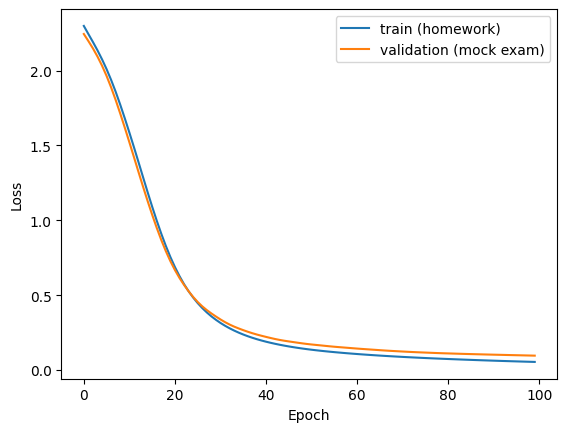

In [ ]:
torch.manual_seed(42)             
              # the same random start for everyone
digit_model = Net(n_inputs=64, n_hidden=32, n_outputs=10)

digit_trainer = Trainer(digit_model, nn.CrossEntropyLoss(), lr=0.01)

digit_trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)

print(digit_model)
print("Weights + biases learned:", sum(p.numel() for p in digit_model.parameters()))
digit_trainer.plot()                            # both lines should go down

### Step 5: final exam
- For each picture the network gives **10 scores**.
- `argmax` = the position of the **biggest** score = the guessed digit.

In [14]:
scores = digit_trainer.predict(X_test_t)        # 10 scores for every test picture, shape (360, 10)
print("Scores for the first picture:", scores[0].round(decimals=1))

guesses = scores.argmax(dim=1).numpy()          # position of the biggest score in each row
print("First 10 guesses:", guesses[:10])
print("First 10 answers:", y_test[:10])

accuracy = (guesses == y_test).mean() * 100     # True = 1, False = 0 → the mean is the share of right guesses
print("Final exam accuracy:", round(accuracy, 1), "%")

Scores for the first picture: tensor([-1.0000, -2.2000, -3.9000, -5.5000, -1.2000, -3.3000,  8.5000, -6.4000,
         1.9000, -2.4000])
First 10 guesses: [6 9 3 7 2 1 5 2 5 2]
First 10 answers: [6 9 3 7 2 1 5 2 5 2]
Final exam accuracy: 96.7 %


### Step 6: look at 16 answers
Green = right, red = wrong.

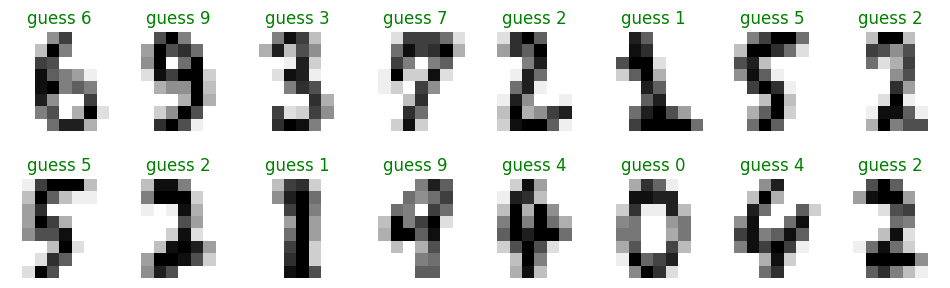

In [15]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))               # 2 rows × 8 small pictures
for i, ax in enumerate(axes.flat):                              # .flat = go through all 16 boxes, one by one
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")           # 64 numbers back into an 8 × 8 picture
    color = "green" if guesses[i] == y_test[i] else "red"       # right → green, wrong → red
    ax.set_title(f"guess {guesses[i]}", color=color)
    ax.axis("off")
plt.show()

## ✅ Complete code
All the steps in one cell. You can run this cell alone.

X: (1797, 64)   y: (1797,)
First picture, first 8 pixels: [0.     0.     0.3125 0.8125 0.5625 0.0625 0.     0.    ]
First 10 answers: [0 1 2 3 4 5 6 7 8 9]
train: 1077   validation: 360   test: 360
torch.float32 torch.Size([1077, 64])
torch.int64 tensor([2, 6, 3, 4, 6, 7, 9, 8, 1, 6])
Net(
  (hidden): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=32, out_features=10, bias=True)
)
Weights + biases learned: 2410


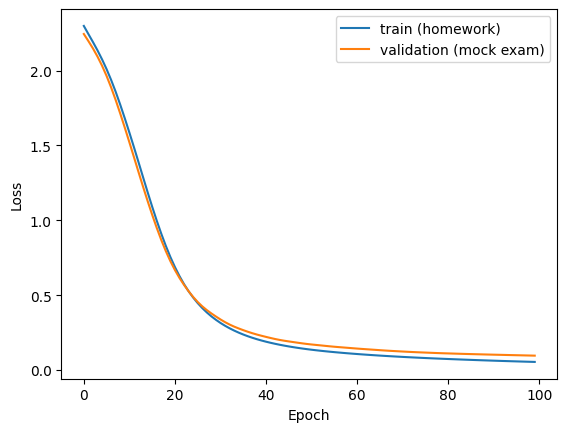

Scores for the first picture: tensor([-1.0000, -2.2000, -3.9000, -5.5000, -1.2000, -3.3000,  8.5000, -6.4000,
         1.9000, -2.4000])
First 10 guesses: [6 9 3 7 2 1 5 2 5 2]
First 10 answers: [6 9 3 7 2 1 5 2 5 2]
Final exam accuracy: 96.7 %


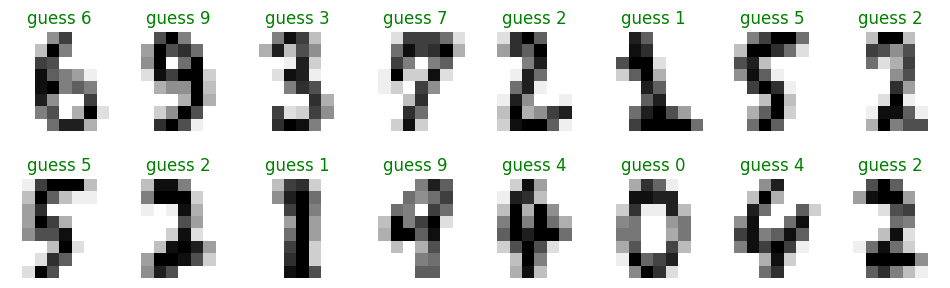

In [16]:
import numpy as np                                     # arrays of numbers
import matplotlib.pyplot as plt                        # draw pictures and charts
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # nn = "neural network": layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split data into train / validation / test
from sklearn.datasets import load_digits               # the handwritten digits pictures


def to_tensor(a, dtype=torch.float32):
    return torch.tensor(a, dtype=dtype)


class Net(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs):
        super().__init__()                          # start the nn.Module part
        self.hidden = nn.Linear(n_inputs, n_hidden) # input → hidden (weights + biases)
        self.relu = nn.ReLU()                       # activation: negative → 0
        self.output = nn.Linear(n_hidden, n_outputs)# hidden → output

    def forward(self, x):
        return self.output(self.relu(self.hidden(x)))


class Trainer:
    def __init__(self, model, loss_fn, lr):
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []

    def fit(self, X_train, y_train, X_val, y_val, epochs):
        for epoch in range(epochs):
            loss = self.loss_fn(self.model(X_train), y_train)   # 1. guess + 2. how wrong
            self.optimizer.zero_grad()                          # 3. clear old blame
            loss.backward()                                     # 4. find blame (backprop)
            self.optimizer.step()                               # 5. fix (gradient descent)
            self.train_losses.append(loss.item())
            with torch.no_grad():                               # mock exam: check only
                self.val_losses.append(self.loss_fn(self.model(X_val), y_val).item())

    def predict(self, X):
        with torch.no_grad():
            return self.model(X)

    def plot(self):
        plt.plot(self.train_losses, label="train (homework)")
        plt.plot(self.val_losses, label="validation (mock exam)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()


# ---------- Step 1 ----------
digits = load_digits()                          # 1797 small pictures (8 × 8 pixels) of handwritten digits
X = digits.data / 16                            # pixels are 0 (white) .. 16 (black) → /16 makes them 0..1
y = digits.target                               # the real digit (0 to 9) for each picture
print("X:", X.shape, "  y:", y.shape)           # (1797, 64) and (1797,)
print("First picture, first 8 pixels:", X[0][:8])
print("First 10 answers:", y[:10])

# ---------- Step 2 ----------
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)            # take out the final exam (20%)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42) # rest → homework (60%) + mock exam (20%)
print("train:", len(X_train), "  validation:", len(X_val), "  test:", len(X_test))

# ---------- Step 3 ----------
X_train_t = to_tensor(X_train)                  # pixels → decimal tensors (float32)
X_val_t = to_tensor(X_val)
X_test_t = to_tensor(X_test)
y_train_t = to_tensor(y_train, torch.long)      # answers → WHOLE numbers (long)
y_val_t = to_tensor(y_val, torch.long)
print(X_train_t.dtype, X_train_t.shape)         # torch.float32, (1077, 64)
print(y_train_t.dtype, y_train_t[:10])          # torch.int64, whole numbers

# ---------- Step 4 ----------
torch.manual_seed(42)                           # the same random start for everyone
digit_model = Net(n_inputs=64, n_hidden=32, n_outputs=10)
digit_trainer = Trainer(digit_model, nn.CrossEntropyLoss(), lr=0.01)
digit_trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)
print(digit_model)
print("Weights + biases learned:", sum(p.numel() for p in digit_model.parameters()))
digit_trainer.plot()                            # both lines should go down

# ---------- Step 5 ----------
scores = digit_trainer.predict(X_test_t)        # 10 scores for every test picture, shape (360, 10)
print("Scores for the first picture:", scores[0].round(decimals=1))

guesses = scores.argmax(dim=1).numpy()          # position of the biggest score in each row
print("First 10 guesses:", guesses[:10])
print("First 10 answers:", y_test[:10])

accuracy = (guesses == y_test).mean() * 100     # True = 1, False = 0 → the mean is the share of right guesses
print("Final exam accuracy:", round(accuracy, 1), "%")

# ---------- Step 6 ----------
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))               # 2 rows × 8 small pictures
for i, ax in enumerate(axes.flat):                              # .flat = go through all 16 boxes, one by one
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")           # 64 numbers back into an 8 × 8 picture
    color = "green" if guesses[i] == y_test[i] else "red"       # right → green, wrong → red
    ax.set_title(f"guess {guesses[i]}", color=color)
    ax.axis("off")
plt.show()

### Why `CrossEntropyLoss`, not `MSELoss`?

**What does the network give?** For each picture: **10 scores**, one for each digit 0 … 9. The biggest score = the guess.

**What does `CrossEntropyLoss` do?** 2 small steps:
1. **softmax:** turn the 10 scores into **10 chances** that add up to 100%.
2. Look **only at the chance of the right digit**. Loss = −log(that chance).

| Chance given to the right digit | Loss | Meaning |
|---|---|---|
| 0.90 (90%) | **0.11** | sure and right → small loss ✓ |
| 0.50 (50%) | **0.69** | not sure → medium loss |
| 0.10 (10%) | **2.30** | almost sure of a wrong digit → big loss ✗ |
| 0.01 (1%) | **4.61** | very sure and wrong → very big loss ✗✗ |

So the network learns: **give the right digit a big chance.**

**Why not `MSELoss`?**
- MSE is for **numbers**, like marks or prices. 52 is close to 55, so a small error is OK.
- Digits here are **groups (classes)**, not amounts. A "7" is not "a bit more than a 6". If the network guessed **6.5** for a 7, that means nothing.
- With MSE, guessing a **1** for a **7** would be "more wrong" than guessing a **6**. But both are simply **wrong**.
- `CrossEntropyLoss` does not care about the size of the digit. It only asks: **how much chance did you give the right one?** And it punishes a **sure, wrong** guess the most.

| Problem | Answer | Loss |
|---|---|---|
| Maths mark, house price | a **number** | `nn.MSELoss()` |
| Which digit, spam or not | a **class** | `nn.CrossEntropyLoss()` |

(Remember Logistic Regression in Class 19: it also gives a **chance**, not a number. Same idea.)